# Pre-Training Model AR-MLP untuk Prediksi Energi (TinyML / ESP32)
Notebook ini sudah diperbaiki: urutan sel, dokumentasi vs kode, ekspor parameter target ke header C++, penanganan celah data, dan pembanding baseline.

In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

tf.keras.utils.set_random_seed(42)

## 0. Prapemrosesan Data Mentah UCI
- Data per menit di-resample ke blok 15 menit, lalu kW dikonversi ke kWh (kW × 0,25 jam).
- Interpolasi linear **dibatasi maksimal 180 menit** dan hanya di dalam rentang data (`limit_area="inside"`). Celah yang lebih panjang dibiarkan `NaN` lalu dibuang pada `dropna()`, supaya tidak terbentuk garis lurus palsu.
- `SCALE_FACTOR` hanya mengubah skala profil ke hunian 1300 VA (asumsi). Nilainya tidak di-clip.

In [29]:
import numpy as np
import pandas as pd

# 1. Baca data mentah UCI
df_raw = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

# 2. Gabungkan kolom Date dan Time menjadi kolom Datetime
df_raw["Datetime"] = pd.to_datetime(
    df_raw["Date"] + " " + df_raw["Time"], 
    format="%d/%m/%Y %H:%M:%S"
)

# 3. Jadikan kolom Datetime sebagai indeks (Index berubah dari RangeIndex menjadi DatetimeIndex)
df_raw.set_index("Datetime", inplace=True)

# 4. Interpolasi nilai kosong (maksimal celah 3 jam)
series_kw = df_raw["Global_active_power"].interpolate(
    method="linear", limit=180, limit_area="inside"
)

# 5. Resample interval 15 menit dan konversi kW ke kWh (kW * 0.25 jam)
df_15m = pd.DataFrame()
df_15m["energy_kwh"] = series_kw.resample("15min").mean() * 0.25

# 6. FILTER BULAN "IKLIM TROPIS / INDONESIA" (Mei s.d. September)
# Sekarang .index.month sudah bisa dipanggil tanpa error
df_15m = df_15m[df_15m.index.month.isin([5, 6, 7, 8, 9])]

# 7. Skalakan ke profil hunian 1300 VA
SCALE_FACTOR = 1300.0 / 6000.0
df_15m["energy_kwh"] = df_15m["energy_kwh"] * SCALE_FACTOR

# ==============================================================
# REKAYASA FITUR (8 FITUR + 4 TARGET)
# ==============================================================
df_features = pd.DataFrame(index=df_15m.index)
hours_decimal = df_15m.index.hour + (df_15m.index.minute / 60.0)

# Fitur 0 - 3: 4 Lag Konsumsi (1 jam terakhir)
df_features["x0_energy_t0"] = df_15m["energy_kwh"]
df_features["x1_energy_t1"] = df_15m["energy_kwh"].shift(1)
df_features["x2_energy_t2"] = df_15m["energy_kwh"].shift(2)
df_features["x3_energy_t3"] = df_15m["energy_kwh"].shift(3)

# Fitur 4: Baseline 6 Jam Terdekat
df_features["x4_baseline_0_6h"] = df_15m["energy_kwh"].shift(1).rolling(24).mean()

# Fitur 5: Konsumsi Jam yang Sama Kemarin (24 jam lalu = 96 blok)
df_features["x5_lag_24h"] = df_15m["energy_kwh"].shift(96)

# Fitur 6 - 7: Siklus Waktu Sirkadian Jam
df_features["x6_hour_sin"] = np.sin(2 * np.pi * hours_decimal / 24.0)
df_features["x7_hour_cos"] = np.cos(2 * np.pi * hours_decimal / 24.0)

# Target Horizon Q1 - Q4 (Masing-masing 6 jam = 24 blok)
df_features["target_q1_0_6h"] = sum(df_15m["energy_kwh"].shift(-i) for i in range(1, 25))
df_features["target_q2_6_12h"] = sum(df_15m["energy_kwh"].shift(-i) for i in range(25, 49))
df_features["target_q3_12_18h"] = sum(df_15m["energy_kwh"].shift(-i) for i in range(49, 73))
df_features["target_q4_18_24h"] = sum(df_15m["energy_kwh"].shift(-i) for i in range(73, 97))

# Buang baris NaN akibat shifting
dataset_final = df_features.dropna()

# Simpan ke CSV dengan menyertakan indeks Datetime
dataset_final.to_csv("tinyml_energy_features.csv", index=True, index_label="Datetime")

print("Prapemrosesan berhasil!")
print(f"Jumlah sampel musim hangat/tropis: {len(dataset_final)}")

Prapemrosesan berhasil!
Jumlah sampel musim hangat/tropis: 56758


## 1. Pemisahan Fitur ($X$), Target ($Y$), dan Pembagian Train-Val-Test
Data dibagi kronologis tanpa pengacakan dengan rasio 70% latih, 15% validasi, 15% uji untuk mencegah kebocoran data masa depan (*lookahead bias*).

> Catatan: karena pembagian kronologis, test set berada di bulan-bulan akhir dataset (kira-kira musim semi hingga gugur 2010), sedangkan train didominasi musim dingin. Sebagian error di test bisa berasal dari pergeseran musim, bukan dari model.

In [30]:
df = pd.read_csv("tinyml_energy_features.csv", index_col="Datetime", parse_dates=True)

feature_cols = [
    "x0_energy_t0",
    "x1_energy_t1",
    "x2_energy_t2",
    "x3_energy_t3",
    "x4_baseline_0_6h",
    "x5_lag_24h",
    "x6_hour_sin",
    "x7_hour_cos",
]
target_cols = [
    "target_q1_0_6h",
    "target_q2_6_12h",
    "target_q3_12_18h",
    "target_q4_18_24h",
]

X = df[feature_cols].values
Y = df[target_cols].values

n_total = len(X)
train_end = int(n_total * 0.70)
val_end = int(n_total * 0.85)

X_train, Y_train = X[:train_end], Y[:train_end]
X_val, Y_val = X[train_end:val_end], Y[train_end:val_end]
X_test, Y_test = X[val_end:], Y[val_end:]

print(f"X_train = {X_train.shape}, Y_train = {Y_train.shape}")
print(f"X_val   = {X_val.shape}, X_test = {X_test.shape}")
print("Rentang test:", df.index[val_end], "->", df.index[-1])

X_train = (39730, 8), Y_train = (39730, 4)
X_val   = (8514, 8), X_test = (8514, 8)
Rentang test: 2010-06-20 22:30:00 -> 2010-09-29 23:45:00


## 2. Standarisasi Fitur dan Target (Z-Score)
Parameter $\mu$ dan $\sigma$ dihitung hanya dari data latih, lalu diterapkan ke data validasi dan uji:

$$x_{norm} = \frac{x - \mu}{\sigma + \epsilon}$$

In [31]:
mean_X = np.mean(X_train, axis=0)
std_X = np.std(X_train, axis=0) + 1e-7
mean_Y = np.mean(Y_train, axis=0)
std_Y = np.std(Y_train, axis=0) + 1e-7

X_train_norm = (X_train - mean_X) / std_X
X_val_norm = (X_val - mean_X) / std_X
X_test_norm = (X_test - mean_X) / std_X

Y_train_norm = (Y_train - mean_Y) / std_Y
Y_val_norm = (Y_val - mean_Y) / std_Y

np.save("feature_mean.npy", mean_X)
np.save("feature_std.npy", std_X)
np.save("target_mean.npy", mean_Y)
np.save("target_std.npy", std_Y)

print(f"X_train_norm = {X_train_norm.shape}, Y_train_norm = {Y_train_norm.shape}")

X_train_norm = (39730, 8), Y_train_norm = (39730, 4)


## 3. Pipeline Data `tf.data.Dataset`
Batch size 128 untuk gradien yang lebih stabil pada data bervolume besar. Hanya data latih yang di-shuffle.

In [32]:
BATCH_SIZE = 128

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_norm, Y_train_norm))
    .shuffle(20000, seed=42)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)
val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_norm, Y_val_norm))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

## 4. Arsitektur Model AR-MLP ($8 \to 24 \to 12 \to 4$)
- Dua hidden layer: Dense 24 dan Dense 12, masing-masing dengan aktivasi LeakyReLU (slope 0,01).
- **Tanpa regularisasi L2**, agar model lebih responsif terhadap lonjakan konsumsi.
- Loss **Huber** ($\delta=1.0$) yang robust terhadap lonjakan ekstrem (*power spikes*), dihitung pada target ternormalisasi.

In [33]:
LEAKY_SLOPE = 0.01

model = models.Sequential([
    layers.Input(shape=(8,), name="input_features"),
    layers.Dense(24, name="hidden_layer_1"),
    layers.LeakyReLU(negative_slope=LEAKY_SLOPE),
    layers.Dense(12, name="hidden_layer_2"),
    layers.LeakyReLU(negative_slope=LEAKY_SLOPE),
    layers.Dense(4, activation="linear", name="output_horizons"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=tf.keras.losses.Huber(delta=1.0),
    metrics=["mae"],
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 24)             │           216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 24)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 12)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_horizons (Dense)         │ (None, 4)              │            52 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 568 (2.22 KB)

 Trainable params: 568 (2.22 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Pelatihan (EarlyStopping & ReduceLROnPlateau)
- `ReduceLROnPlateau`: menurunkan laju belajar saat loss validasi mendatar.
- `EarlyStopping`: berhenti jika tidak ada perbaikan selama 15 epoch dan memulihkan bobot terbaik.

In [34]:
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-5, verbose=1
)
early_stop = EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True, verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=200,
    callbacks=[early_stop, reduce_lr],
)

Epoch 1/200


/home/ridho/ngoding/IoT Prediksi kWh/pelatihan/.venv/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


311/311 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.3527 - mae: 0.7099 - val_loss: 0.3422 - val_mae: 0.6833 - learning_rate: 0.0010
Epoch 2/200
311/311 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3047 - mae: 0.6381 - val_loss: 0.3115 - val_mae: 0.6392 - learning_rate: 0.0010
Epoch 3/200
311/311 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2918 - mae: 0.6182 - val_loss: 0.3020 - val_mae: 0.6258 - learning_rate: 0.0010
Epoch 4/200
311/311 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2872 - mae: 0.6105 - val_loss: 0.2956 - val_mae: 0.6191 - learning_rate: 0.0010
Epoch 5/200
311/311 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2846 - mae: 0.6064 - val_loss: 0.2935 - val_mae: 0.6171 - learning_rate: 0.0010
Epoch 6/200
311/311 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2827 - mae: 0.6030 - val_loss: 0.2950 - val_mae: 0.6167 - learning_rate: 0.0010
Epoch 7/200
311/311 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2817 - mae: 0.6011 - val_loss: 0.2924 - val_mae: 0.6149 - learning_rate: 0.0010
Epoch 8/200

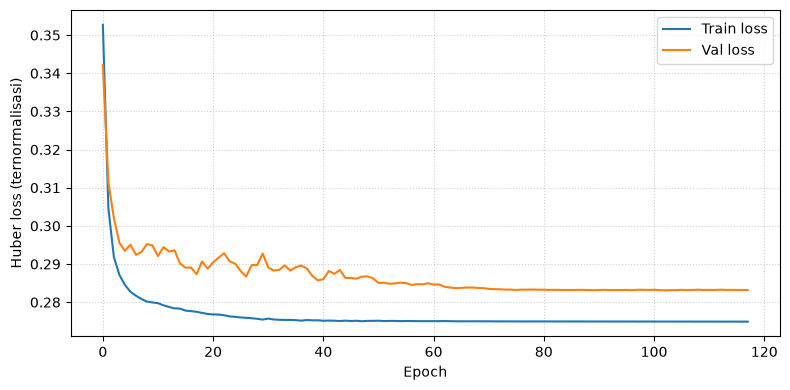

In [35]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Huber loss (ternormalisasi)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

## 6. Menyimpan Model Dasar (Pre-Trained)

In [36]:
model.save("pretrained_energy_model.keras")
model.save_weights("pretrained_weights.weights.h5")
print("Model dasar dan bobot optimal berhasil disimpan!")

Model dasar dan bobot optimal berhasil disimpan!


## 7. Ekspor ke Header C++ untuk ESP32
Header memuat parameter normalisasi fitur **dan target**, bobot, serta dimensi layer.

Catatan implementasi di sisi ESP32:
- Bobot Keras Dense berbentuk `(in, out)` dan di-flatten per baris, sehingga elemen `W[i][j]` berada di indeks `W[i * out + j]`.
- Aktivasi hidden layer adalah LeakyReLU: `y = x > 0 ? x : LEAKY_SLOPE * x`.
- Fitur `x6`/`x7` dihitung sebagai `sin/cos(2π · jam_desimal / 24)`.
- Output model masih ternormalisasi. Kembalikan ke kWh dengan `y * TARGET_STD[k] + TARGET_MEAN[k]`, lalu `max(0, y)`.

In [37]:
mean_X = np.load("feature_mean.npy")
std_X = np.load("feature_std.npy")
mean_Y = np.load("target_mean.npy")
std_Y = np.load("target_std.npy")

w1, b1 = model.get_layer("hidden_layer_1").get_weights()
w2, b2 = model.get_layer("hidden_layer_2").get_weights()
w3, b3 = model.get_layer("output_horizons").get_weights()


def to_c_array(arr, name):
    flat = arr.flatten()
    s = f"const float {name}[{len(flat)}] = {{\n  "
    s += ", ".join([f"{v:.7f}f" for v in flat])
    s += "\n};\n"
    return s


with open("tinyml_model.h", "w") as f:
    f.write("#ifndef TINYML_MODEL_H\n#define TINYML_MODEL_H\n\n")

    f.write("// Dimensi jaringan: 8 -> 24 -> 12 -> 4\n")
    f.write(f"#define N_INPUT {w1.shape[0]}\n")
    f.write(f"#define N_HIDDEN1 {w1.shape[1]}\n")
    f.write(f"#define N_HIDDEN2 {w2.shape[1]}\n")
    f.write(f"#define N_OUTPUT {w3.shape[1]}\n")
    f.write("const float LEAKY_SLOPE = 0.01f;  // aktivasi LeakyReLU hidden layer\n\n")

    f.write("// Normalisasi Z-Score fitur: x_norm = (x - mean) / std\n")
    f.write(to_c_array(mean_X, "FEATURE_MEAN"))
    f.write(to_c_array(std_X, "FEATURE_STD"))

    f.write("\n// Denormalisasi target: y_kwh = y_norm * std + mean (lalu max(0, y))\n")
    f.write(to_c_array(mean_Y, "TARGET_MEAN"))
    f.write(to_c_array(std_Y, "TARGET_STD"))

    f.write("\n// Layer 1 (Dense 8 -> 24), W[i * N_HIDDEN1 + j]\n")
    f.write(to_c_array(w1, "W_LAYER1"))
    f.write(to_c_array(b1, "B_LAYER1"))

    f.write("\n// Layer 2 (Dense 24 -> 12), W[i * N_HIDDEN2 + j]\n")
    f.write(to_c_array(w2, "W_LAYER2"))
    f.write(to_c_array(b2, "B_LAYER2"))

    f.write("\n// Output (Dense 12 -> 4, linear), W[i * N_OUTPUT + j]\n")
    f.write(to_c_array(w3, "W_LAYER3"))
    f.write(to_c_array(b3, "B_LAYER3"))

    f.write("\n#endif // TINYML_MODEL_H\n")

print("Ekspor selesai! tinyml_model.h siap digunakan pada sketch Arduino ESP32.")

Ekspor selesai! tinyml_model.h siap digunakan pada sketch Arduino ESP32.


## 8. Evaluasi pada Test Set Independen
Prediksi di-denormalisasi ke kWh dan dipotong agar tidak negatif ($Q_m \ge 0$). Model dibandingkan dengan dua baseline:
- **Baseline rata-rata latih**: selalu memprediksi `mean_Y`.
- **Baseline persisten**: rata-rata 6 jam terakhir (`x4_baseline_0_6h`) × 24 blok.

Model baru dianggap berguna jika MAE-nya lebih kecil daripada kedua baseline.

In [38]:
# Inferensi (skala ternormalisasi) lalu denormalisasi ke kWh
Y_test_pred = model.predict(X_test_norm, batch_size=BATCH_SIZE, verbose=0) * std_Y + mean_Y
Y_test_pred = np.maximum(0.0, Y_test_pred)

# Baseline
Y_base_mean = np.tile(mean_Y, (len(Y_test), 1))
idx_base = feature_cols.index("x4_baseline_0_6h")
Y_base_persist = np.repeat((X_test[:, idx_base] * 24.0)[:, None], 4, axis=1)


def mape(y_true, y_pred, thr=0.05):
    m = y_true > thr
    return np.mean(np.abs((y_true[m] - y_pred[m]) / y_true[m])) * 100


overall_mae = mean_absolute_error(Y_test, Y_test_pred)
overall_rmse = np.sqrt(mean_squared_error(Y_test, Y_test_pred))
print("Hasil Evaluasi (Test Set)")
print(f" - Model            -> MAE: {overall_mae:.4f} kWh | RMSE: {overall_rmse:.4f} kWh")
print(f" - Baseline rata2   -> MAE: {mean_absolute_error(Y_test, Y_base_mean):.4f} kWh")
print(f" - Baseline persist -> MAE: {mean_absolute_error(Y_test, Y_base_persist):.4f} kWh")
print(f" - Rata-rata target test: {Y_test.mean():.4f} kWh\n")

horizons = ["0-6 Jam (Q1)", "6-12 Jam (Q2)", "12-18 Jam (Q3)", "18-24 Jam (Q4)"]
for i, h in enumerate(horizons):
    mae_h = mean_absolute_error(Y_test[:, i], Y_test_pred[:, i])
    rmse_h = np.sqrt(mean_squared_error(Y_test[:, i], Y_test_pred[:, i]))
    mae_p = mean_absolute_error(Y_test[:, i], Y_base_persist[:, i])
    print(
        f" - {h} -> MAE: {mae_h:.4f} | RMSE: {rmse_h:.4f} | "
        f"MAPE: {mape(Y_test[:, i], Y_test_pred[:, i]):.2f}% | MAE persisten: {mae_p:.4f}"
    )

Hasil Evaluasi (Test Set)
 - Model            -> MAE: 0.3400 kWh | RMSE: 0.4564 kWh
 - Baseline rata2   -> MAE: 0.4393 kWh
 - Baseline persist -> MAE: 0.4471 kWh
 - Rata-rata target test: 0.9990 kWh

 - 0-6 Jam (Q1) -> MAE: 0.3462 | RMSE: 0.4636 | MAPE: 45.27% | MAE persisten: 0.5031
 - 6-12 Jam (Q2) -> MAE: 0.3390 | RMSE: 0.4531 | MAPE: 40.28% | MAE persisten: 0.4326
 - 12-18 Jam (Q3) -> MAE: 0.3610 | RMSE: 0.4842 | MAPE: 47.81% | MAE persisten: 0.5212
 - 18-24 Jam (Q4) -> MAE: 0.3136 | RMSE: 0.4224 | MAPE: 36.88% | MAE persisten: 0.3318


## 9. Visualisasi Prediksi vs Aktual (Horizon Q1: 0-6 Jam)

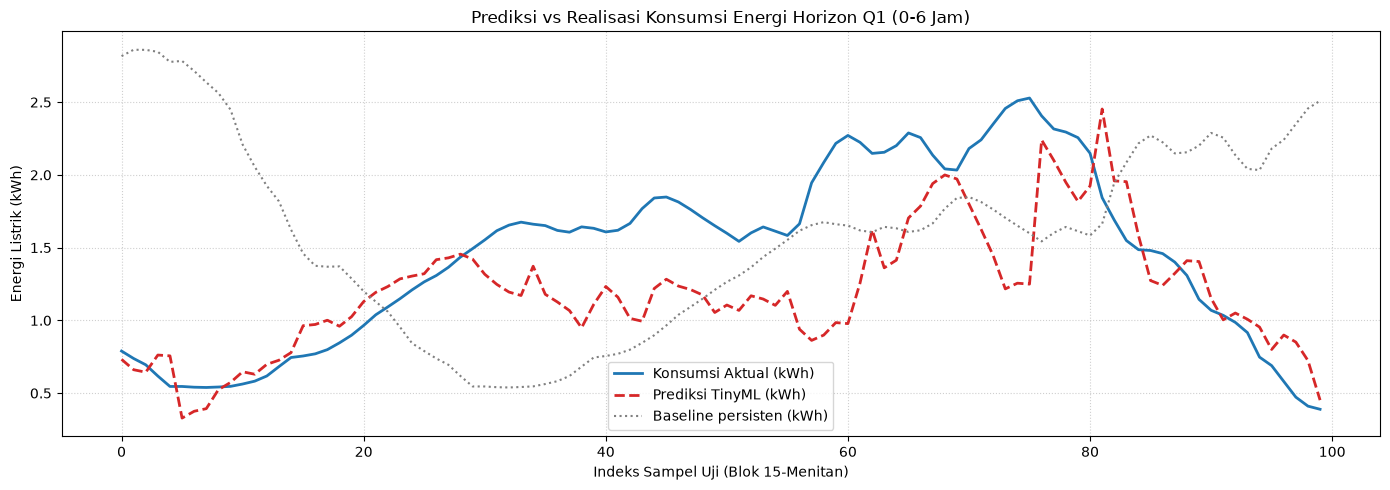

In [39]:
n_plot = 100
plt.figure(figsize=(14, 5))
plt.plot(Y_test[:n_plot, 0], label="Konsumsi Aktual (kWh)", color="#1f77b4", linewidth=2)
plt.plot(Y_test_pred[:n_plot, 0], label="Prediksi TinyML (kWh)", color="#d62728",
         linestyle="--", linewidth=2)
plt.plot(Y_base_persist[:n_plot, 0], label="Baseline persisten (kWh)", color="gray",
         linestyle=":", linewidth=1.5)
plt.title("Prediksi vs Realisasi Konsumsi Energi Horizon Q1 (0-6 Jam)")
plt.xlabel("Indeks Sampel Uji (Blok 15-Menitan)")
plt.ylabel("Energi Listrik (kWh)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()